# Final Project — Regression Analysis
**Business 35137 — Winter 2026**

Weather-augmented Fama-French panel regressions examining whether county-level weather shocks
explain excess stock returns for agriculture, leisure, and utility companies.

**Design:**
- Two-step benchmark: Step A = FF3 only; Step B = FF3 + weather variables
- 3 lag variants (T, T-1, T-3) × 6 sample cuts = 18 benchmarked pairs (36 regressions)
- PanelOLS with Ticker Fixed Effects, standard errors clustered by ticker

In [1]:
import subprocess, sys
subprocess.check_call([sys.executable, '-m', 'pip', 'install', 'linearmodels', '-q'])

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import warnings
import os

from linearmodels.panel import PanelOLS

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:.4f}'.format)

In [2]:
# ── Paths ──────────────────────────────────────────────────────────────────────
DATA_DIR = '../Data/Intermediate/'
OUT_DIR  = '../Data/Intermediate/'
os.makedirs(OUT_DIR, exist_ok=True)

# ── Sample cuts ────────────────────────────────────────────────────────────────
# atmos_sector values: 'Agriculture & Food', 'Leisure & Tourism', 'Utilities & Telecom'
# index values:        'S&P 500' (Large Cap), 'Russell 2000' (Small Cap)

SAMPLE_CUTS = {
    'Full Sample'  : {},
    'Food'         : {'atmos_sector': 'Agriculture & Food'},
    'Entertainment': {'atmos_sector': 'Leisure & Tourism'},
    'Utilities'    : {'atmos_sector': 'Utilities & Telecom'},
    'Large Cap'    : {'index': 'S&P 500'},
    'Small Cap'    : {'index': 'Russell 2000'},
}

# Cuts that include Industry x Weather interactions
INDUSTRY_INTERACTION_CUTS = {'Full Sample', 'Large Cap', 'Small Cap'}

# Lag variants
LAGS = [0, 1, 3]

# Core weather z-score columns (from panel.parquet)
WEATHER_VARS = ['rainfall_z_score', 'temp_z_score', 'solar_z_score']
WEATHER_PREFIXES = ['rain', 'temp', 'solar']

# Fama-French + risk-free columns to use (fully populated, no duplicates)
FF_COLS = ['mktrf', 'smb', 'hml', 'rf']

In [4]:
# ── Load & Preprocess ──────────────────────────────────────────────────────────
raw = pd.read_parquet(DATA_DIR + 'panel.parquet')

# 1. Temporal filter: drop rows where solar_z_score is null (restricts to 1998+)
df = raw.dropna(subset=['solar_z_score']).copy()

# 2. Log return and excess return
#    ret is already in decimal form (e.g. 0.03 = 3%)
df['log_return']    = np.log(1 + df['ret'])
df['excess_return'] = df['log_return'] - df['rf']

# 3. Drop duplicate FF factor columns (_x and _y suffixes), keep clean versions
df = df.drop(columns=[c for c in df.columns if c.endswith('_x') or c.endswith('_y')], errors='ignore')

# 4. Sort panel for correct lag computation
df = df.sort_values(['permno', 'date']).reset_index(drop=True)

# Observation checks
print(f"Rows after solar filter  : {len(df):,}")
print(f"Companies                : {df['permno'].nunique():,}")
print(f"Date range               : {df['date'].min().date()}  to  {df['date'].max().date()}")
print(f"\nExcess return stats:")
print(df['excess_return'].describe().to_string())
print(f"\nSample by index:")
print(df['index'].value_counts())
print(f"\nSample by sector:")
print(df['atmos_sector'].value_counts())

# Researcher check: verify Small Cap has enough obs for Entertainment and Utilities
print("\n── Small Cap sector check (post-1998) ──")
sc = df[df['index'] == 'Russell 2000']
for sector in ['Leisure & Tourism', 'Utilities & Telecom']:
    n     = (sc['atmos_sector'] == sector).sum()
    n_cos = sc[sc['atmos_sector'] == sector]['permno'].nunique()
    print(f"  {sector}: {n:,} obs | {n_cos} companies")

Rows after solar filter  : 81,001
Companies                : 1,028
Date range               : 1998-01-30  to  2024-12-31

Excess return stats:
count   80859.0000
mean        0.0011
std         0.1366
min        -2.1532
25%        -0.0521
50%         0.0054
75%         0.0589
max         2.5943

Sample by index:
index
Russell 2000    54215
S&P 500         26786
Name: count, dtype: int64

Sample by sector:
atmos_sector
Utilities & Telecom    43447
Leisure & Tourism      22072
Agriculture & Food     15482
Name: count, dtype: int64

── Small Cap sector check (post-1998) ──
  Leisure & Tourism: 17,436 obs | 255 companies
  Utilities & Telecom: 27,268 obs | 480 companies


In [5]:
# ── Feature Engineering ────────────────────────────────────────────────────────

def build_features(base_df, lag):
    """
    Build the full feature set for a given lag (0, 1, or 3).

    Returns
    -------
    df           : DataFrame with all feature columns added
    weather_cols : lagged weather z-score column names
    extreme_cols : |z|>2 indicator column names
    sector_cols  : sector dummy column names (used to identify reference)
    ind_int_cols : industry x weather interaction column names (all k, trimmed in loop)
    """
    df = base_df.copy()

    # ── Lagged weather z-scores ────────────────────────────────────────────
    if lag == 0:
        weather_cols = WEATHER_VARS.copy()
    else:
        weather_cols = []
        for var in WEATHER_VARS:
            cname = f'{var}_lag{lag}'
            df[cname] = df.groupby('permno')[var].shift(lag)
            weather_cols.append(cname)

    # ── Extreme indicators: 1 if |z| > 2, else 0 ──────────────────────────
    extreme_cols = []
    for col, prefix in zip(weather_cols, WEATHER_PREFIXES):
        cname = f'{prefix}_extreme'
        df[cname] = np.where(df[col].isna(), np.nan, (df[col].abs() > 2).astype(float))
        extreme_cols.append(cname)

    # ── Industry dummies & Weather x Industry interactions ─────────────────
    dummies = pd.get_dummies(df['atmos_sector'], prefix='sec').astype(float)
    sector_cols = list(dummies.columns)
    df = pd.concat([df, dummies], axis=1)

    ind_int_cols = []
    for w_col, w_prefix in zip(weather_cols, WEATHER_PREFIXES):
        for s_col in sector_cols:
            cname = f'{w_prefix}_x_{s_col}'
            df[cname] = df[w_col] * df[s_col]
            ind_int_cols.append(cname)

    return df, weather_cols, extreme_cols, sector_cols, ind_int_cols


# Quick test
_df, _wc, _ec, _ssc, _ic = build_features(df, lag=0)
print(f"Weather cols  : {_wc}")
print(f"Extreme cols  : {_ec}")
print(f"Sector cols   : {_ssc}")
print(f"Industry ints : {len(_ic)} columns  (will trim to k-1 per weather var in loop)")

Weather cols  : ['rainfall_z_score', 'temp_z_score', 'solar_z_score']
Extreme cols  : ['rain_extreme', 'temp_extreme', 'solar_extreme']
Sector cols   : ['sec_Agriculture & Food', 'sec_Leisure & Tourism', 'sec_Utilities & Telecom']
Industry ints : 9 columns  (will trim to k-1 per weather var in loop)


In [6]:
# ── Regression Engine ──────────────────────────────────────────────────────────

def apply_cut(df, cut_filters):
    """Filter dataframe to the sample cut defined by cut_filters dict."""
    mask = pd.Series(True, index=df.index)
    for col, val in cut_filters.items():
        mask &= (df[col] == val)
    return df[mask].copy()


def run_panel_ols(sub_df, feature_cols, entity='permno', time='date'):
    """
    Run PanelOLS with entity (ticker) fixed effects.
    Clustered standard errors by entity.
    Time FE disabled so FF factors are not collinear.

    Returns result object or None on failure.
    """
    panel = sub_df.set_index([entity, time])
    cols  = ['excess_return'] + feature_cols
    panel = panel[cols].dropna()

    if len(panel) < 50 or panel.index.get_level_values(0).nunique() < 5:
        return None

    y = panel['excess_return']
    X = panel[feature_cols]

    try:
        model  = PanelOLS(y, X, entity_effects=True, time_effects=False, drop_absorbed=True)
        result = model.fit(cov_type='clustered', cluster_entity=True)
        return result
    except Exception as e:
        print(f"    Regression error: {e}")
        return None


def extract_results(result, step_label, cut_name, lag):
    """Flatten a PanelOLS result into a dict for the master table."""
    if result is None:
        return None
    rows = []
    params   = result.params
    pvalues  = result.pvalues
    for var in params.index:
        rows.append({
            'cut'      : cut_name,
            'lag'      : f'T-{lag}' if lag > 0 else 'T',
            'step'     : step_label,
            'variable' : var,
            'coef'     : params[var],
            'pvalue'   : pvalues[var],
            'rsq_within' : result.rsquared_within,
            'nobs'     : result.nobs,
        })
    return rows

In [7]:
# ── Execution Loop: 3 lags x 6 cuts = 18 pairs (36 regressions) ───────────────
#
# Step B model per cut type:
#   Sector cuts (Food / Entertainment / Utilities):
#       FF3 + weather_z + extreme_indicator  (no interactions — only one sector)
#   Cross-sector cuts (Full Sample / Large Cap / Small Cap):
#       FF3 + weather_z + extreme_indicator + k-1 weather×sector interactions
#       (k-1 = 2 interactions per weather var, dropping Agriculture & Food as reference)

all_rows      = []
summary_rows  = []
stored_results = {}

FF_FEATURES = ['mktrf', 'smb', 'hml']

for lag in LAGS:
    lag_label = f'T-{lag}' if lag > 0 else 'T'
    print(f"\n=== Lag: {lag_label} ===")

    feat_df, weather_cols, extreme_cols, sector_cols, ind_int_cols = build_features(df, lag)

    # Reference sector: first alphabetically from pd.get_dummies (Agriculture & Food)
    ref_sector = sector_cols[0] if sector_cols else None

    for cut_name, cut_filters in SAMPLE_CUTS.items():
        print(f"  {cut_name} ...", end=' ')
        sub = apply_cut(feat_df, cut_filters)

        # ── Step A: FF3 Benchmark ──────────────────────────────────────────
        res_a = run_panel_ols(sub, FF_FEATURES)
        rows_a = extract_results(res_a, 'Step A (FF3)', cut_name, lag)
        if rows_a:
            all_rows.extend(rows_a)

        # ── Step B: Weather-Augmented Model ───────────────────────────────
        include_ind = cut_name in INDUSTRY_INTERACTION_CUTS
        if include_ind and ref_sector:
            # Drop reference sector's interactions to avoid collinearity
            # (all 3 interactions would sum back to the raw z-score)
            trimmed_int_cols = [c for c in ind_int_cols if not c.endswith(ref_sector)]
        else:
            trimmed_int_cols = []

        full_feats = FF_FEATURES + weather_cols + extreme_cols + trimmed_int_cols

        res_b = run_panel_ols(sub, full_feats)
        rows_b = extract_results(res_b, 'Step B (Full)', cut_name, lag)
        if rows_b:
            all_rows.extend(rows_b)

        # ── Summary row ────────────────────────────────────────────────────
        rsq_a = res_a.rsquared_within if res_a else np.nan
        rsq_b = res_b.rsquared_within if res_b else np.nan
        summary_rows.append({
            'Cut'      : cut_name,
            'Lag'      : lag_label,
            'FF3 R2'   : rsq_a,
            'Full R2'  : rsq_b,
            'R2 Lift'  : rsq_b - rsq_a if not np.isnan(rsq_a + rsq_b) else np.nan,
            'Nobs (B)' : res_b.nobs if res_b else np.nan,
        })
        stored_results[(cut_name, lag_label)] = {
            'A': res_a, 'B': res_b, 'weather_cols': weather_cols
        }

        status = 'OK' if (res_a and res_b) else 'PARTIAL' if (res_a or res_b) else 'FAILED'
        print(status)

print("\nDone. Total regressions attempted:", len(LAGS) * len(SAMPLE_CUTS) * 2)


=== Lag: T ===
  Full Sample ... OK
  Food ... OK
  Entertainment ... OK
  Utilities ... OK
  Large Cap ... OK
  Small Cap ... OK

=== Lag: T-1 ===
  Full Sample ... OK
  Food ... OK
  Entertainment ... OK
  Utilities ... OK
  Large Cap ... OK
  Small Cap ... OK

=== Lag: T-3 ===
  Full Sample ... OK
  Food ... OK
  Entertainment ... OK
  Utilities ... OK
  Large Cap ... OK
  Small Cap ... OK

Done. Total regressions attempted: 36


In [8]:
# ── Results Table ──────────────────────────────────────────────────────────────

results_df = pd.DataFrame(all_rows)
summary_df = pd.DataFrame(summary_rows)

# ── Summary table ──────────────────────────────────────────────────────────────
summary_display = summary_df.copy()
for col in ['FF3 R2', 'Full R2', 'R2 Lift']:
    summary_display[col] = summary_display[col].map('{:.4f}'.format)
summary_display['Nobs (B)'] = summary_display['Nobs (B)'].map(
    lambda x: f"{int(x):,}" if not pd.isna(x) else 'N/A'
)

print("═" * 72)
print("SUMMARY TABLE — R² Comparison (Within R²)")
print("═" * 72)
print(summary_display.to_string(index=False))

# ── Weather coefficient table ──────────────────────────────────────────────────
WEATHER_PATTERNS = (
    WEATHER_VARS
    + [f'{v}_lag1' for v in WEATHER_VARS]
    + [f'{v}_lag3' for v in WEATHER_VARS]
    + [f'{p}_extreme' for p in WEATHER_PREFIXES]
    + [f'{p}_x_' for p in WEATHER_PREFIXES]
)

def is_weather(varname):
    return any(varname == kw or varname.startswith(kw) for kw in WEATHER_PATTERNS)

weather_coefs = results_df[
    (results_df['step'] == 'Step B (Full)') &
    (results_df['variable'].apply(is_weather))
].copy()

weather_coefs['sig'] = weather_coefs['pvalue'].apply(
    lambda p: '***' if p < 0.01 else ('**' if p < 0.05 else ('*' if p < 0.10 else ''))
)

print("\n\n" + "═" * 72)
print("WEATHER COEFFICIENT TABLE — Step B (Full Model)")
print("═" * 72)
display_cols = ['cut', 'lag', 'variable', 'coef', 'pvalue', 'sig', 'nobs']
print(weather_coefs[display_cols].to_string(index=False, float_format='{:.4f}'.format))

# ── Save to CSV ────────────────────────────────────────────────────────────────
results_df.to_csv(OUT_DIR + 'regression_results_all.csv', index=False)
summary_df.to_csv(OUT_DIR + 'regression_summary.csv', index=False)
weather_coefs.to_csv(OUT_DIR + 'weather_coefficients.csv', index=False)

print(f"\nSaved:")
print(f"  regression_results_all.csv  ({len(results_df):,} rows)")
print(f"  regression_summary.csv      ({len(summary_df):,} rows)")
print(f"  weather_coefficients.csv    ({len(weather_coefs):,} rows)")

════════════════════════════════════════════════════════════════════════
SUMMARY TABLE — R² Comparison (Within R²)
════════════════════════════════════════════════════════════════════════
          Cut Lag FF3 R2 Full R2 R2 Lift Nobs (B)
  Full Sample   T 0.1355  0.1361  0.0006   77,623
         Food   T 0.1033  0.1053  0.0020   15,052
Entertainment   T 0.2181  0.2165 -0.0016   21,320
    Utilities   T 0.1165  0.1172  0.0007   41,251
    Large Cap   T 0.1646  0.1664  0.0018   25,919
    Small Cap   T 0.1454  0.1458  0.0003   51,704
  Full Sample T-1 0.1355  0.1384  0.0029   76,787
         Food T-1 0.1033  0.1060  0.0027   14,904
Entertainment T-1 0.2181  0.2203  0.0022   21,098
    Utilities T-1 0.1165  0.1192  0.0026   40,785
    Large Cap T-1 0.1646  0.1669  0.0022   25,765
    Small Cap T-1 0.1454  0.1484  0.0030   51,022
  Full Sample T-3 0.1355  0.1382  0.0027   74,919
         Food T-3 0.1033  0.1048  0.0015   14,592
Entertainment T-3 0.2181  0.2210  0.0030   20,595
    Utilitie

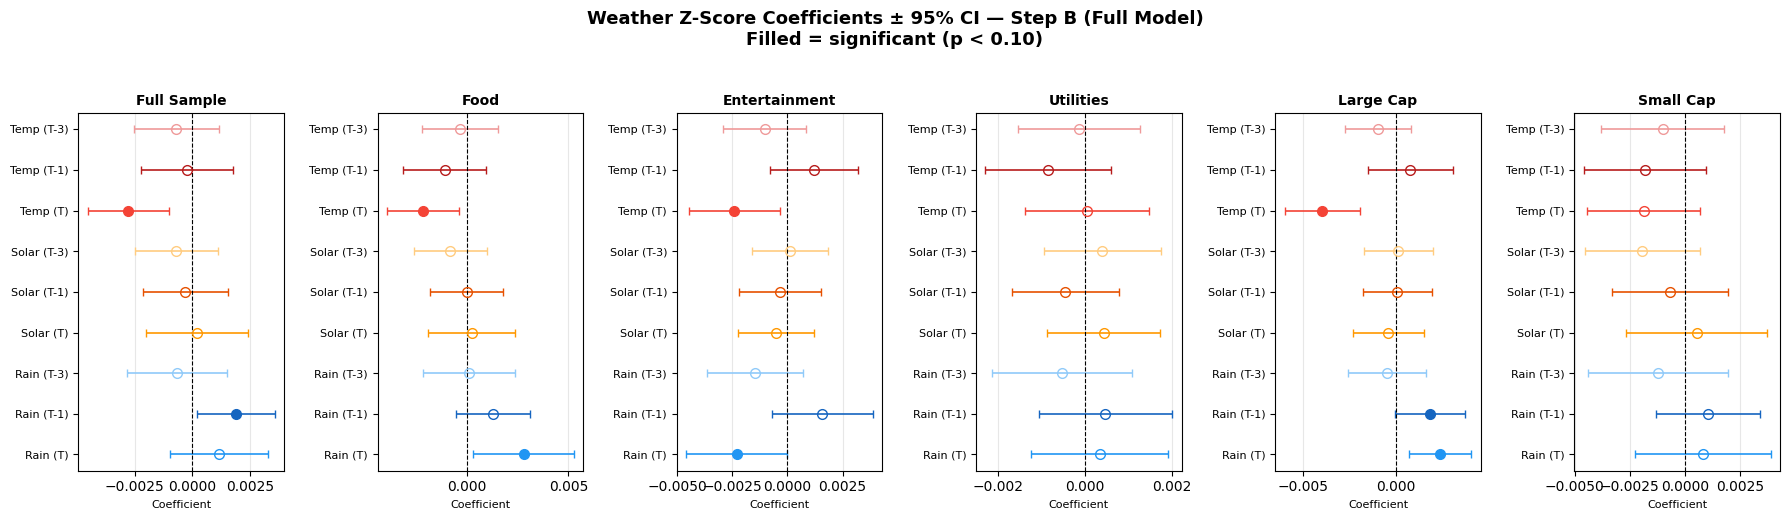

Saved: fig2_weather_coefficients.png


In [10]:
# ── Figure 2: Weather Coefficient Dot Plot ────────────────────────────────────
# Coefficient ± 95% CI for each weather z-score term, by sample cut.
# Filled dot = significant (p < 0.10); hollow = not significant.

LINEAR_WEATHER = (
    WEATHER_VARS
    + [f'{v}_lag1' for v in WEATHER_VARS]
    + [f'{v}_lag3' for v in WEATHER_VARS]
)

dot_data = results_df[
    (results_df['step'] == 'Step B (Full)') &
    (results_df['variable'].isin(LINEAR_WEATHER))
].copy()

# Pull standard errors from stored result objects
se_rows = []
for (cut_name, lag_lbl), res_dict in stored_results.items():
    res_b = res_dict.get('B')
    if res_b is None:
        continue
    for var in res_b.params.index:
        if var in LINEAR_WEATHER:
            se_rows.append({
                'cut': cut_name, 'lag': lag_lbl, 'variable': var,
                'se': res_b.std_errors[var]
            })

se_df    = pd.DataFrame(se_rows)
dot_data = dot_data.merge(se_df, on=['cut', 'lag', 'variable'], how='left')
dot_data['ci95'] = 1.96 * dot_data['se']

VAR_SHORT = {
    'rainfall_z_score'      : 'Rain (T)',
    'temp_z_score'          : 'Temp (T)',
    'solar_z_score'         : 'Solar (T)',
    'rainfall_z_score_lag1' : 'Rain (T-1)',
    'temp_z_score_lag1'     : 'Temp (T-1)',
    'solar_z_score_lag1'    : 'Solar (T-1)',
    'rainfall_z_score_lag3' : 'Rain (T-3)',
    'temp_z_score_lag3'     : 'Temp (T-3)',
    'solar_z_score_lag3'    : 'Solar (T-3)',
}
dot_data['var_short'] = dot_data['variable'].map(VAR_SHORT)
dot_data['sig']       = dot_data['pvalue'] < 0.10

CUT_ORDER = ['Full Sample', 'Food', 'Entertainment', 'Utilities', 'Large Cap', 'Small Cap']

fig, axes = plt.subplots(1, len(CUT_ORDER), figsize=(18, 5), sharey=False)
fig.suptitle('Weather Z-Score Coefficients ± 95% CI — Step B (Full Model)\n'
             'Filled = significant (p < 0.10)',
             fontsize=13, fontweight='bold', y=1.03)

COLORS = {
    'Rain (T)' : '#2196F3', 'Temp (T)' : '#F44336', 'Solar (T)' : '#FF9800',
    'Rain (T-1)': '#1565C0', 'Temp (T-1)': '#B71C1C', 'Solar (T-1)': '#E65100',
    'Rain (T-3)': '#90CAF9', 'Temp (T-3)': '#EF9A9A', 'Solar (T-3)': '#FFCC80',
}

for ax, cut in zip(axes, CUT_ORDER):
    sub = dot_data[dot_data['cut'] == cut].sort_values('variable').reset_index(drop=True)
    if sub.empty:
        ax.set_visible(False)
        continue

    for i, row in sub.iterrows():
        color = COLORS.get(row['var_short'], 'grey')
        fill  = color if row['sig'] else 'none'
        ax.errorbar(row['coef'], i, xerr=row['ci95'],
                    fmt='o', color=color, markerfacecolor=fill,
                    markeredgecolor=color, markersize=7, capsize=3, lw=1.2)

    ax.axvline(0, color='black', lw=0.8, ls='--')
    ax.set_yticks(range(len(sub)))
    ax.set_yticklabels(sub['var_short'].tolist(), fontsize=8)
    ax.set_title(cut, fontsize=10, fontweight='bold')
    ax.set_xlabel('Coefficient', fontsize=8)
    ax.grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.savefig(OUT_DIR + 'fig2_weather_coefficients.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: fig2_weather_coefficients.png")

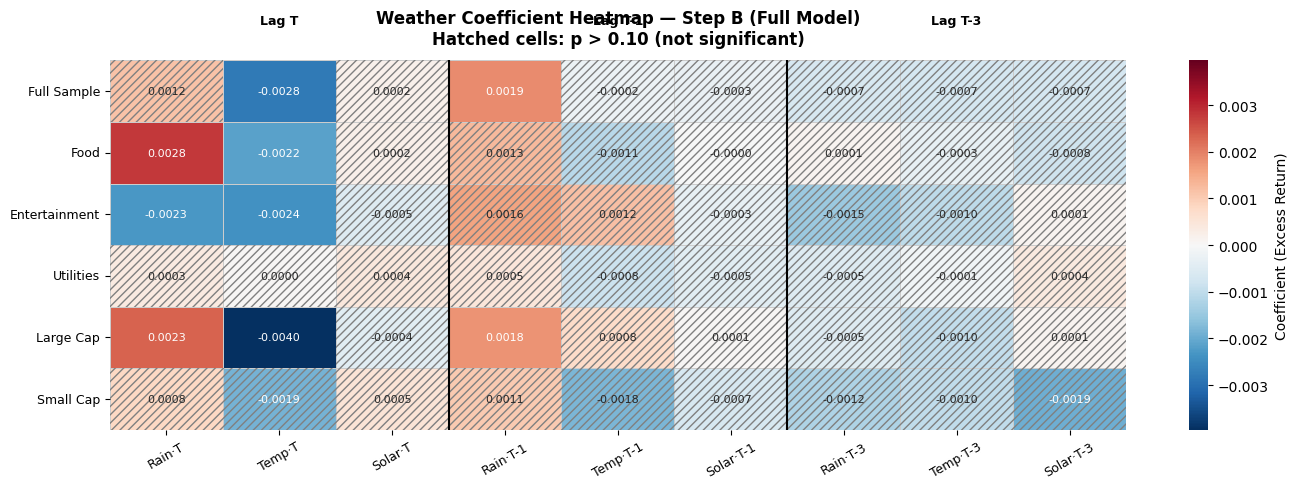

Saved: fig3_coefficient_heatmap.png


In [11]:
# ── Figure 3: Coefficient Heatmap ──────────────────────────────────────────────
# Show significant weather coefficients (linear z-score terms) across lag variants
# Rows = sample cuts, Columns = weather variable x lag combinations
# Cell color = coefficient value; hatched if p > 0.10 (not significant)

# Keep only linear weather z-score terms (exclude splines and interactions)
LINEAR_WEATHER = (WEATHER_VARS
                  + [f'{v}_lag1' for v in WEATHER_VARS]
                  + [f'{v}_lag3' for v in WEATHER_VARS])

hmap_data = results_df[
    (results_df['step'] == 'Step B (Full)') &
    (results_df['variable'].isin(LINEAR_WEATHER))
].copy()

# Shorten variable names for display
VAR_SHORT = {
    'rainfall_z_score'       : 'Rain·T',
    'temp_z_score'           : 'Temp·T',
    'solar_z_score'          : 'Solar·T',
    'rainfall_z_score_lag1'  : 'Rain·T-1',
    'temp_z_score_lag1'      : 'Temp·T-1',
    'solar_z_score_lag1'     : 'Solar·T-1',
    'rainfall_z_score_lag3'  : 'Rain·T-3',
    'temp_z_score_lag3'      : 'Temp·T-3',
    'solar_z_score_lag3'     : 'Solar·T-3',
}
hmap_data['var_short'] = hmap_data['variable'].map(VAR_SHORT)

# Pivot: rows = cut, columns = var_short, values = coef
col_order = ['Rain·T', 'Temp·T', 'Solar·T',
             'Rain·T-1', 'Temp·T-1', 'Solar·T-1',
             'Rain·T-3', 'Temp·T-3', 'Solar·T-3']

# For multi-lag, take one row per (cut, var_short) — lags are already in var name
pivot_coef = hmap_data.pivot_table(
    index='cut', columns='var_short', values='coef', aggfunc='mean'
).reindex(index=CUT_ORDER, columns=col_order)

pivot_pval = hmap_data.pivot_table(
    index='cut', columns='var_short', values='pvalue', aggfunc='mean'
).reindex(index=CUT_ORDER, columns=col_order)

# Significance mask: True = NOT significant (p > 0.10) → draw hatch
insig_mask = pivot_pval > 0.10

fig, ax = plt.subplots(figsize=(14, 5))

vmax = pivot_coef.abs().max().max()
if np.isnan(vmax) or vmax == 0:
    vmax = 0.01

sns.heatmap(
    pivot_coef,
    ax=ax,
    cmap='RdBu_r',
    center=0,
    vmin=-vmax,
    vmax=vmax,
    annot=True,
    fmt='.4f',
    linewidths=0.5,
    linecolor='#cccccc',
    cbar_kws={'label': 'Coefficient (Excess Return)'},
    annot_kws={'size': 8},
)

# Overlay hatch on insignificant cells
for i, row in enumerate(CUT_ORDER):
    for j, col in enumerate(col_order):
        try:
            if insig_mask.loc[row, col]:
                ax.add_patch(plt.Rectangle((j, i), 1, 1, fill=False,
                                           hatch='////', edgecolor='grey', lw=0))
        except (KeyError, TypeError):
            pass

# Column separator lines between lag groups
ax.axvline(3, color='black', lw=1.5)
ax.axvline(6, color='black', lw=1.5)
ax.text(1.5, -0.6, 'Lag T',   ha='center', fontsize=9, fontweight='bold', transform=ax.transData)
ax.text(4.5, -0.6, 'Lag T-1', ha='center', fontsize=9, fontweight='bold', transform=ax.transData)
ax.text(7.5, -0.6, 'Lag T-3', ha='center', fontsize=9, fontweight='bold', transform=ax.transData)

ax.set_title('Weather Coefficient Heatmap — Step B (Full Model)\n'
             'Hatched cells: p > 0.10 (not significant)',
             fontsize=12, fontweight='bold', pad=12)
ax.set_xlabel('')
ax.set_ylabel('')
ax.tick_params(axis='x', rotation=30, labelsize=9)
ax.tick_params(axis='y', rotation=0,  labelsize=9)

plt.tight_layout()
plt.savefig(OUT_DIR + 'fig3_coefficient_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: fig3_coefficient_heatmap.png")

In [12]:
# ── OOS R² Analysis (Campbell-Thompson 2008) ───────────────────────────────────
#
# Method: single temporal split — train 1998-2017, test 2018-2024
#   - Respects time ordering; no look-ahead bias
#   - Entity FEs estimated on training data only, applied to test period
#   - Entities in test but unseen in train receive the grand training mean as FE
#
# Metrics reported:
#   OOS R²(A)    = 1 - MSPE(FF3)  / MSPE(prevailing mean)   [Campbell-Thompson]
#   OOS R²(B)    = 1 - MSPE(Full) / MSPE(prevailing mean)
#   ΔOOS R²(B-A) = 1 - MSPE(Full) / MSPE(FF3)               [incremental lift]
#   CW p-value   = one-sided Clark-West test: H1 = Full has lower MSPE than FF3
#                  (adjusts for upward bias from extra parameters in larger model)

from scipy import stats as scipy_stats

TRAIN_CUTOFF = pd.Timestamp('2020-01-01')


def fit_and_predict_oos(sub_df, feature_cols, train_cutoff,
                        entity='permno', time='date'):
    """
    Fit PanelOLS on the training window, predict on the test window.

    Entity FEs are recovered as:
        a_hat[i] = mean_train(y_i) - mean_train(X_i) @ beta_hat
    which is the within-estimator FE formula.

    Returns
    -------
    preds : DataFrame with columns [y_actual, y_hat], MultiIndex (entity, time)
    train_mean : grand mean of excess_return over training period (prevailing mean)
    None, None on failure
    """
    train = sub_df[sub_df[time] < train_cutoff].copy()
    test  = sub_df[sub_df[time] >= train_cutoff].copy()

    cols = ['excess_return'] + feature_cols
    train_p = train.set_index([entity, time])[cols].dropna()
    test_p  = test.set_index([entity, time])[cols].dropna()

    if len(train_p) < 100 or len(test_p) < 30:
        return None, None

    y_tr = train_p['excess_return']
    X_tr = train_p[feature_cols]

    try:
        result = PanelOLS(y_tr, X_tr, entity_effects=True,
                          time_effects=False, drop_absorbed=True
                          ).fit(cov_type='clustered', cluster_entity=True)
    except Exception:
        return None, None

    beta = result.params
    # Only use features that survived drop_absorbed
    active = [f for f in feature_cols if f in beta.index]

    # ── Entity FEs from training data ──────────────────────────────────────
    entity_fe = {}
    for eid in train_p.index.get_level_values(0).unique():
        y_e = y_tr.xs(eid, level=0)
        X_e = X_tr.xs(eid, level=0)[active]
        entity_fe[eid] = float((y_e - X_e @ beta[active]).mean())

    train_mean = float(y_tr.mean())   # prevailing mean benchmark

    # ── Predict on test ────────────────────────────────────────────────────
    y_te  = test_p['excess_return']
    X_te  = test_p[active]
    eids  = y_te.index.get_level_values(0)
    fe_v  = np.array([entity_fe.get(e, train_mean) for e in eids])

    y_hat = (X_te @ beta[active]).values + fe_v

    preds = pd.DataFrame(
        {'y_actual': y_te.values, 'y_hat': y_hat},
        index=y_te.index
    )
    return preds, train_mean


def campbell_thompson_r2(y_actual, y_hat, benchmark_scalar):
    """R²_OOS = 1 - MSPE(model) / MSPE(prevailing mean)."""
    mspe_model = np.mean((y_actual - y_hat) ** 2)
    mspe_bench = np.mean((y_actual - benchmark_scalar) ** 2)
    return 1.0 - mspe_model / mspe_bench


def clark_west_pvalue(y, y_hat_a, y_hat_b):
    """
    Clark-West (2007) MSPE-adjusted test: H1 = Model B has lower MSPE than A.
    f_t = (y - y_hat_A)^2 - [(y - y_hat_B)^2 - (y_hat_A - y_hat_B)^2]
    Reject H0 (equal predictability) when mean(f_t) > 0.
    Returns one-sided p-value.
    """
    e_a = y - y_hat_a
    e_b = y - y_hat_b
    f_t = e_a**2 - (e_b**2 - (y_hat_a - y_hat_b)**2)
    t_stat = np.mean(f_t) / (np.std(f_t, ddof=1) / np.sqrt(len(f_t)))
    return float(1.0 - scipy_stats.norm.cdf(t_stat))   # one-sided


# ── Main OOS Loop ──────────────────────────────────────────────────────────────
oos_rows = []

print(f"Train window : 1998-01 to {TRAIN_CUTOFF.date() - pd.DateOffset(days=1)}")
print(f"Test  window : {TRAIN_CUTOFF.date()} to 2024-12-31\n")

for lag in LAGS:
    lag_label = f'T-{lag}' if lag > 0 else 'T'
    feat_df, weather_cols, extreme_cols, sector_cols, ind_int_cols = build_features(df, lag)
    ref_sector = sector_cols[0] if sector_cols else None

    for cut_name, cut_filters in SAMPLE_CUTS.items():
        sub = apply_cut(feat_df, cut_filters)

        # Step A features
        feats_a = FF_FEATURES

        # Step B features (same logic as in-sample loop)
        include_ind = cut_name in INDUSTRY_INTERACTION_CUTS
        trimmed_int = ([c for c in ind_int_cols if not c.endswith(ref_sector)]
                       if (include_ind and ref_sector) else [])
        feats_b = FF_FEATURES + weather_cols + extreme_cols + trimmed_int

        preds_a, mean_a = fit_and_predict_oos(sub, feats_a, TRAIN_CUTOFF)
        preds_b, mean_b = fit_and_predict_oos(sub, feats_b, TRAIN_CUTOFF)

        if preds_a is None or preds_b is None:
            print(f"  SKIP {cut_name} {lag_label}")
            continue

        # Align on common test observations (Step B may drop more NaNs)
        common_idx = preds_a.index.intersection(preds_b.index)
        pa = preds_a.loc[common_idx]
        pb = preds_b.loc[common_idx]
        y  = pa['y_actual'].values          # identical for both after alignment

        oos_r2_a   = campbell_thompson_r2(y, pa['y_hat'].values, mean_a)
        oos_r2_b   = campbell_thompson_r2(y, pb['y_hat'].values, mean_b)
        delta_oos  = campbell_thompson_r2(y, pb['y_hat'].values,
                                          pa['y_hat'].values)   # B vs A as benchmark
        cw_pval    = clark_west_pvalue(y, pa['y_hat'].values, pb['y_hat'].values)

        oos_rows.append({
            'Cut'         : cut_name,
            'Lag'         : lag_label,
            'OOS R2 (A)'  : oos_r2_a,
            'OOS R2 (B)'  : oos_r2_b,
            'ΔOOS R2'     : delta_oos,
            'CW p-val'    : cw_pval,
            'N test'      : len(y),
        })
        print(f"  {cut_name:15s} {lag_label:4s} | "
              f"OOS-A={oos_r2_a:+.4f}  OOS-B={oos_r2_b:+.4f}  "
              f"ΔOOS={delta_oos:+.4f}  CW-p={cw_pval:.3f}")

oos_df = pd.DataFrame(oos_rows)
oos_df.to_csv(OUT_DIR + 'oos_r2_results.csv', index=False)
print(f"\nSaved: oos_r2_results.csv  ({len(oos_df)} rows)")

Train window : 1998-01 to 2019-12-31 00:00:00
Test  window : 2020-01-01 to 2024-12-31

  Full Sample     T    | OOS-A=+0.1783  OOS-B=+0.1789  ΔOOS=+0.0008  CW-p=0.001
  Food            T    | OOS-A=+0.1078  OOS-B=+0.1092  ΔOOS=+0.0016  CW-p=0.022
  Entertainment   T    | OOS-A=+0.3300  OOS-B=+0.3290  ΔOOS=-0.0015  CW-p=0.776
  Utilities       T    | OOS-A=+0.1125  OOS-B=+0.1128  ΔOOS=+0.0004  CW-p=0.025
  Large Cap       T    | OOS-A=+0.2800  OOS-B=+0.2823  ΔOOS=+0.0033  CW-p=0.000
  Small Cap       T    | OOS-A=+0.1747  OOS-B=+0.1750  ΔOOS=+0.0004  CW-p=0.069
  Full Sample     T-1  | OOS-A=+0.1793  OOS-B=+0.1981  ΔOOS=+0.0229  CW-p=0.000
  Food            T-1  | OOS-A=+0.1063  OOS-B=+0.1049  ΔOOS=-0.0012  CW-p=0.692
  Entertainment   T-1  | OOS-A=+0.3307  OOS-B=+0.3304  ΔOOS=-0.0003  CW-p=0.194
  Utilities       T-1  | OOS-A=+0.1142  OOS-B=+0.1543  ΔOOS=+0.0453  CW-p=0.000
  Large Cap       T-1  | OOS-A=+0.2804  OOS-B=+0.2815  ΔOOS=+0.0015  CW-p=0.008
  Small Cap       T-1  | OOS-A=+0

════════════════════════════════════════════════════════════════════════════════════════════════════
IS vs OOS R² — Full Comparison (test window: 2020-2024)
════════════════════════════════════════════════════════════════════════════════════════════════════
          Cut Lag IS R2 (A) IS R2 (B)  ΔIS R2 OOS R2 (A) OOS R2 (B) ΔOOS R2 CW p-val N test
  Full Sample   T   +0.1355   +0.1361 +0.0006    +0.1783    +0.1789 +0.0008    0.001 11,089
         Food   T   +0.1033   +0.1053 +0.0020    +0.1078    +0.1092 +0.0016    0.022  2,423
Entertainment   T   +0.2181   +0.2165 -0.0016    +0.3300    +0.3290 -0.0015    0.776  3,137
    Utilities   T   +0.1165   +0.1172 +0.0007    +0.1125    +0.1128 +0.0004    0.025  5,529
    Large Cap   T   +0.1646   +0.1664 +0.0018    +0.2800    +0.2823 +0.0033    0.000  4,691
    Small Cap   T   +0.1454   +0.1458 +0.0003    +0.1747    +0.1750 +0.0004    0.069  6,398
  Full Sample T-1   +0.1355   +0.1384 +0.0029    +0.1793    +0.1981 +0.0229    0.000 11,050
      

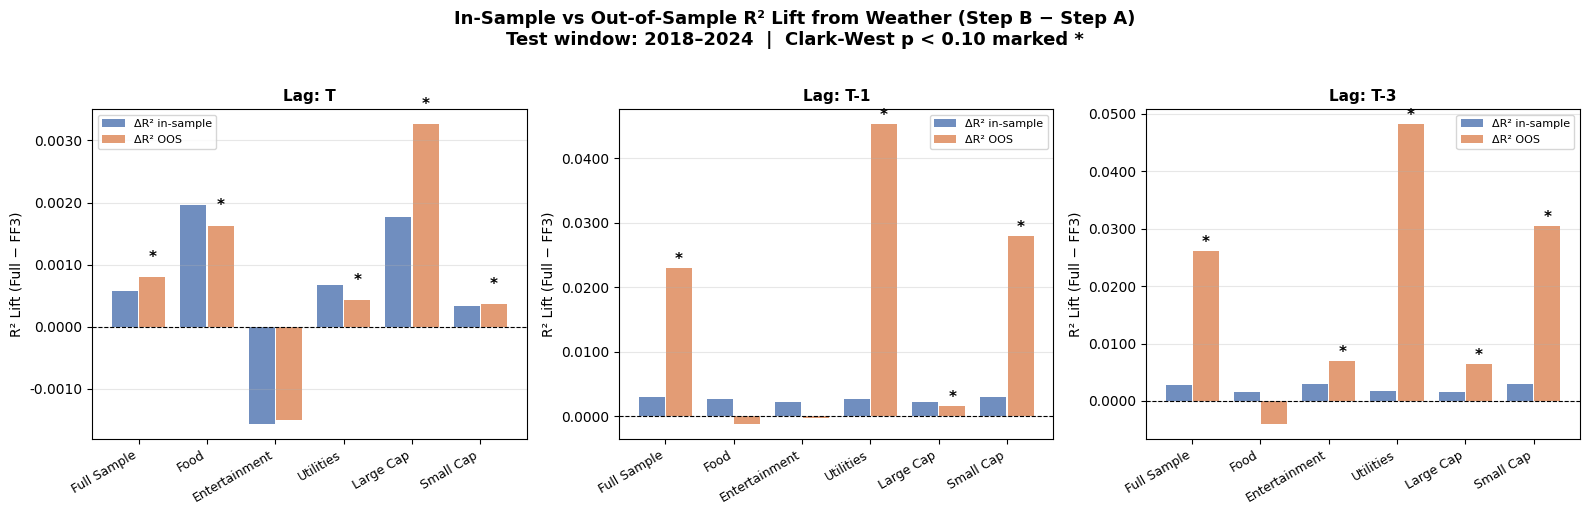

Saved: fig4_is_vs_oos_lift.png


In [14]:
# ── Figure 4 + Summary Table: IS vs OOS R² ────────────────────────────────────

# Merge in-sample summary into oos_df for side-by-side comparison
is_lookup = summary_df.set_index(['Cut', 'Lag'])[['FF3 R2', 'Full R2', 'R2 Lift']]
oos_merged = oos_df.join(is_lookup, on=['Cut', 'Lag'])
oos_merged = oos_merged.rename(columns={
    'FF3 R2' : 'IS R2 (A)',
    'Full R2': 'IS R2 (B)',
    'R2 Lift': 'ΔIS R2',
})

# ── Print combined table ───────────────────────────────────────────────────────
print("═" * 100)
print("IS vs OOS R² — Full Comparison (test window: 2020-2024)")
print("═" * 100)
disp = oos_merged.copy()
for c in ['IS R2 (A)', 'IS R2 (B)', 'ΔIS R2', 'OOS R2 (A)', 'OOS R2 (B)', 'ΔOOS R2']:
    disp[c] = disp[c].map('{:+.4f}'.format)
disp['CW p-val'] = disp['CW p-val'].map('{:.3f}'.format)
disp['N test']   = disp['N test'].map('{:,}'.format)
print(disp[['Cut','Lag','IS R2 (A)','IS R2 (B)','ΔIS R2',
            'OOS R2 (A)','OOS R2 (B)','ΔOOS R2','CW p-val','N test']
     ].to_string(index=False))

# ── Figure 4: IS vs OOS Δ R² scatter/bar ──────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharey=False)
fig.suptitle('In-Sample vs Out-of-Sample R² Lift from Weather (Step B − Step A)\n'
             'Test window: 2018–2024  |  Clark-West p < 0.10 marked *',
             fontsize=13, fontweight='bold', y=1.02)

for ax, lag_lbl in zip(axes, LAG_ORDER):
    sub = oos_merged[oos_merged['Lag'] == lag_lbl].copy()

    x     = np.arange(len(sub))
    is_l  = sub['ΔIS R2'].astype(float).values
    oos_l = sub['ΔOOS R2'].astype(float).values
    cw_p  = sub['CW p-val'].astype(float).values
    cuts  = sub['Cut'].tolist()

    bars_is  = ax.bar(x - 0.2, is_l,  0.38, label='ΔR² in-sample',  color='#4C72B0', alpha=0.80)
    bars_oos = ax.bar(x + 0.2, oos_l, 0.38, label='ΔR² OOS',        color='#DD8452', alpha=0.80)

    # Star for CW-significant OOS bars
    for xi, (oos_val, p) in enumerate(zip(oos_l, cw_p)):
        if p < 0.10:
            ax.text(xi + 0.2, oos_val + (0.0002 if oos_val >= 0 else -0.0008),
                    '*', ha='center', va='bottom', fontsize=11, color='black', fontweight='bold')

    ax.axhline(0, color='black', lw=0.8, ls='--')
    ax.set_title(f'Lag: {lag_lbl}', fontsize=11, fontweight='bold')
    ax.set_xticks(x)
    ax.set_xticklabels(cuts, rotation=30, ha='right', fontsize=9)
    ax.set_ylabel('R² Lift (Full − FF3)')
    ax.yaxis.set_major_formatter(mticker.FormatStrFormatter('%.4f'))
    ax.legend(fontsize=8)
    ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig(OUT_DIR + 'fig4_is_vs_oos_lift.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: fig4_is_vs_oos_lift.png")